In [1]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt


DATA_DIR = Path("../Data")

print("chemin : ",DATA_DIR.resolve())#le chemin complet
print("le doccier existe :",DATA_DIR.exists())#virifier si le doccier exist

# les nom des doccier

# if DATA_DIR.exists():
#     print("Contenu du doccier data :")
#     for ele in DATA_DIR.iterdir():
#         print(ele.name)


class_names=[]
for ele in DATA_DIR.iterdir():
    class_names.append(ele.name)
# print(class_names)


extensions_valides={".jpg",".jpeg",".png",".bmp"}

image_counts={}

for class_name in class_names:
    class_dir=DATA_DIR / class_name

    images = [
        file
        for file in class_dir.rglob("*")
        if file.is_file()
        and file.suffix.lower() in extensions_valides
    ]

    image_counts[class_name]=len(images)


print("le nombre dimage par class :")
# print(image_counts)
for class_name ,count in image_counts.items():
    print(f"{class_name} : {count} images")

chemin :  C:\BrainScan\Data
le doccier existe : True
le nombre dimage par class :
glioma : 1621 images
meningioma : 1645 images
notumor : 2000 images
pituitary : 1757 images
processed : 0 images


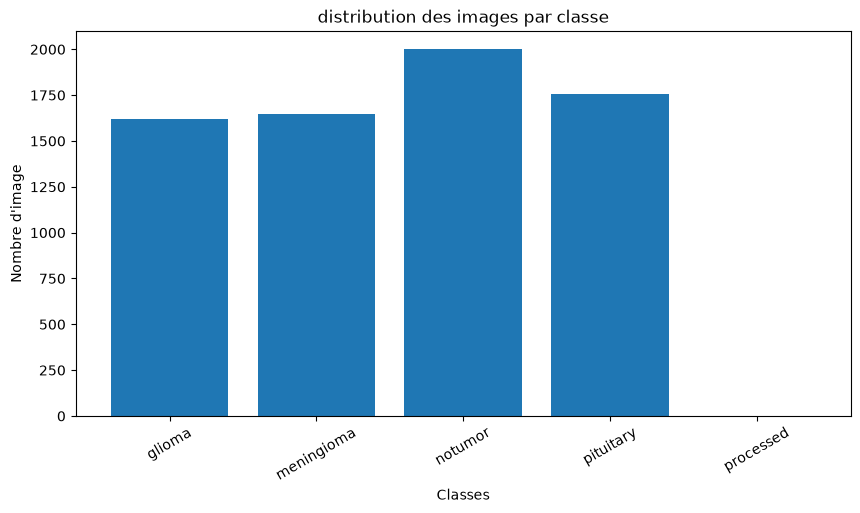

In [2]:
plt.figure(figsize=(10,5))

plt.bar(
    image_counts.keys(),
    image_counts.values()
)

plt.title("distribution des images par classe")
plt.xlabel("Classes")
plt.ylabel("Nombre d'image")
plt.xticks(rotation=30)
plt.show()

# print(image_counts)

In [3]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

# recuperer le chemains des imgs
image_path=[]
labels=[]

for class_name in class_names:
    class_dir=DATA_DIR/ class_name

    for file in class_dir.rglob("*"):
        if file.is_file() and file.suffix.lower() in extensions_valides:
            image_path.append(file)
            labels.append(class_name)


print("Nombre de chemins :",len(image_path))
print("Nombre de labels :",len(labels))

# print(image_path)
# print(labels)


Nombre de chemins : 7023
Nombre de labels : 7023


In [4]:
# virifier que image est lisible

if image_path:
    try:
        image=Image.open(image_path[0])
        image.verify()#virifier si li file valide ou non 

        print("image valide :",image_path[0])
        print("Format : ",image.format)
        print("Dimension :",image.size)
    except Exception as error:
        print("erreur :",error)
else:
    print("aucun img trouve")

image valide : ..\Data\glioma\Te-glTr_0000.jpg
Format :  JPEG
Dimension : (512, 512)


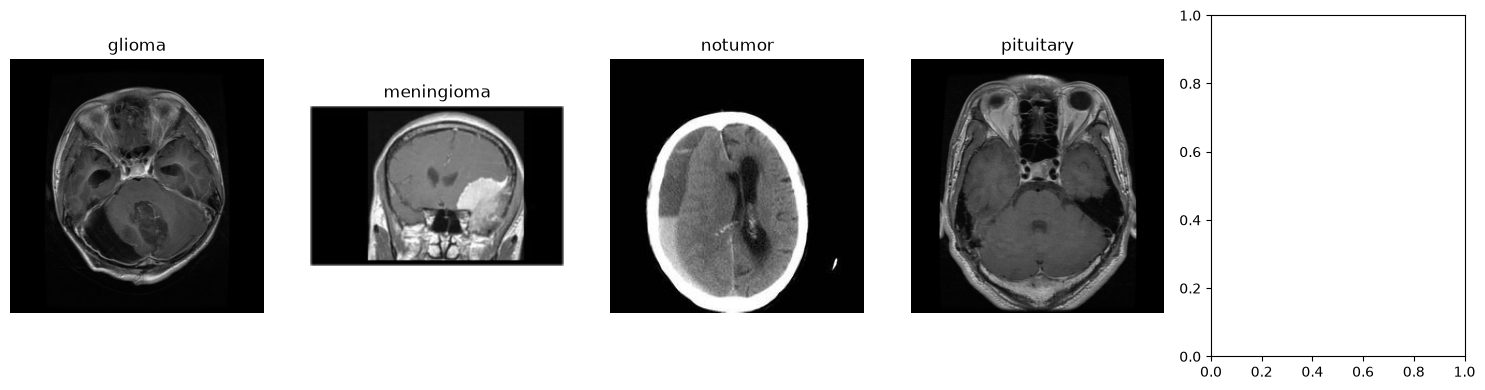

In [5]:
# afficher quelque img avce leur labels

fig,axes=plt.subplots(1,len(class_names),figsize=(15,4))#crer 4 espace

for ax,class_name in zip(axes,class_names):#associer chque  image a son label
    class_images=[
        path for path,label in zip(image_path,labels)
        if label == class_name
    ]

    if class_images:
        try:
            with Image.open(class_images[0]) as image:
                ax.imshow(image.convert("RGB"))#convertit limg en trois canaux de couleur pour faciliter leur affichage

            ax.set_title(class_name)
            ax.axis("off")#masque les axes inutiles
        except Exception as error:
            ax.set_title(f"erreur : {class_name}")
            ax.axis("off")
            print(class_name,error)

plt.tight_layout()
plt.show()

In [6]:
# nettoyer et preparer les imgs

valide_paths=[]
valide_labels=[]
invalid_img=[]

for path,label in zip(image_path,labels):
    try:
        with Image.open(path) as img:
            img.verify()

        valide_paths.append(path)
        valide_labels.append(label)
    except Exception as error:
        invalid_img.append((path,str(error)))

print("images trouve :",len(image_path))
print("image valides :",len(valide_paths))
print("image invalides :",len(invalid_img))

images trouve : 7023
image valides : 7023
image invalides : 0


In [7]:
import hashlib

# dictionnaire pour stocker les empreintes des images
images_hash = {}

doublons = []

for classe in DATA_DIR.iterdir():

    if not classe.is_dir():
        continue

    # parcourir les imgs du dossier
    for image in classe.rglob("*"):

        if image.suffix.lower() not in extensions_valides:
            continue

        try:
            # lire le contenu de l'img
            with open(image, "rb") as fichier:
                empreinte = hashlib.sha256(fichier.read()).hexdigest()

            # verifier si cette img existe deja
            if empreinte in images_hash:
                doublons.append((images_hash[empreinte], image))
            else:
                images_hash[empreinte] = image

        except OSError:
            print("erreur de lecture :", image)

# afficher les resultats
print("nombre d'images analysees :", len(images_hash) + len(doublons))
print("nombre de doublons trouves :", len(doublons))


nombre d'images analysees : 7023
nombre de doublons trouves : 297


In [8]:
# doublons avce leur class

for image1,image2 in doublons:
    class1=image1.parent.name
    class2=image2.parent.name
    print("image 1 :", image1, "| classe :", class1)
    print("image 2 :", image2, "| classe :", class2)
    print("-" * 50)

image 1 : ..\Data\glioma\Te-gl_0024.jpg | classe : glioma
image 2 : ..\Data\glioma\Te-gl_0029.jpg | classe : glioma
--------------------------------------------------
image 1 : ..\Data\meningioma\Te-me_0010.jpg | classe : meningioma
image 2 : ..\Data\meningioma\Te-me_0031.jpg | classe : meningioma
--------------------------------------------------
image 1 : ..\Data\meningioma\Te-me_0071.jpg | classe : meningioma
image 2 : ..\Data\meningioma\Te-me_0073.jpg | classe : meningioma
--------------------------------------------------
image 1 : ..\Data\meningioma\Te-me_0135.jpg | classe : meningioma
image 2 : ..\Data\meningioma\Tr-me_0071.jpg | classe : meningioma
--------------------------------------------------
image 1 : ..\Data\meningioma\Tr-me_0176.jpg | classe : meningioma
image 2 : ..\Data\meningioma\Tr-me_0211.jpg | classe : meningioma
--------------------------------------------------
image 1 : ..\Data\meningioma\Tr-me_0227.jpg | classe : meningioma
image 2 : ..\Data\meningioma\Tr-me_

In [9]:
#
meme_class=0
class_diff=0
for image1,image2 in doublons:
    if image1.parent.name == image2.parent.name:
        meme_class+=1
    else:
        class_diff +=1

print("doublons dans la meme classe :", meme_class)
print("doublons entre classes differentes :", class_diff)

doublons dans la meme classe : 297
doublons entre classes differentes : 0


In [10]:
# garder une copie d'image

images_uniques = {}
doublons = []

for classe in DATA_DIR.iterdir():
    if not classe.is_dir():
        continue

    for image in classe.rglob("*"):
        if image.suffix.lower() not in extensions_valides:
            continue

        # calculer l'empreinte de l'image
        with open(image, "rb") as fichier:
            empreinte = hashlib.sha256(fichier.read()).hexdigest()

        # garder la premiere image trouvee
        if empreinte not in images_uniques:
            images_uniques[empreinte] = (image, classe.name)
        else:
            doublons.append(image)

# creer les listes sans doublons
image_paths = []
labels = []

for image, label in images_uniques.values():
    image_paths.append(image)
    labels.append(label)

print("images uniques :", len(image_paths))
print("doublons ignores :", len(doublons))


images uniques : 6726
doublons ignores : 297


In [11]:
# melange les images

import random

random.seed(42)

data=list(zip(image_paths,labels))#creation de paire (path,label)
random.shuffle(data)

image_paths,labels = zip(*data)

image_paths = list(image_paths)
labels = list(labels)

print("nombre d'images :",len(image_paths))
print("nombre labels :",len(labels))
print("la premiere class apres melange :",labels[:10])

nombre d'images : 6726
nombre labels : 6726
la premiere class apres melange : ['glioma', 'glioma', 'pituitary', 'meningioma', 'pituitary', 'pituitary', 'notumor', 'pituitary', 'notumor', 'notumor']


In [12]:
# redimensionnement des imgs

IMG_SIZE=(224,224)

images_resized=[]
labels_resized=[]

for path,label in zip(image_paths,labels):
    try:
        with Image.open(path) as img:
            img=img.convert("RGB")#3 canaux
            img=img.resize(IMG_SIZE)

            images_resized.append(np.array(img))#convertit limg en tableau numerique
            labels_resized.append(label)
    except Exception as error:
        print(f"erreur avec {path} : {error}")

x=np.array(images_resized,dtype=np.uint8)
y=np.array(labels_resized)

print("dimensions de x :", x.shape)
print("dimensions de y :", y.shape)

dimensions de x : (6726, 224, 224, 3)
dimensions de y : (6726,)


In [13]:
# normalise les pix

X=x.astype("float32")/255.0
print("Valeur minimale :", X.min())
print("Valeur maximale :", X.max())
print("Type des données :", X.dtype)

Valeur minimale : 0.0
Valeur maximale : 1.0
Type des données : float32


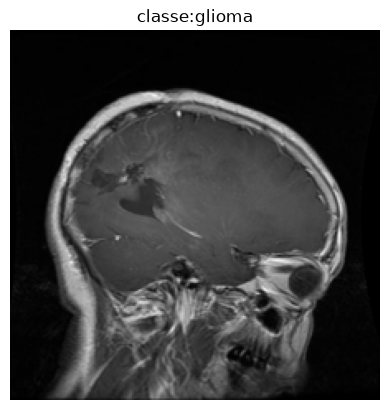

In [14]:

plt.imshow(x[0])
plt.title(f"classe:{y[0]}")
plt.axis("off")
plt.show()

In [15]:
# encoder labels
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import numpy as np

label_encoder=LabelEncoder()

y_encoded=label_encoder.fit_transform(y)


print("class :",label_encoder.classes_)
print("label encodees :",np.unique(y_encoded))

class : ['glioma' 'meningioma' 'notumor' 'pituitary']
label encodees : [0 1 2 3]


In [16]:
# separation des donnee train / test
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.15,
    random_state=42,
    stratify=y_encoded
)
print("train + validation :", X_train_val.shape[0])
print("test :", X_test.shape[0])

train + validation : 5717
test : 1009


In [17]:
# train + val

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.15 / 0.85,
    random_state=42,
    stratify=y_train_val
)

print("train :", len(X_train))
print("validation :", len(X_val))
print("test :", len(X_test))

train : 4708
validation : 1009
test : 1009


In [18]:
# save x_train ...

import os
import numpy as np

os.makedirs("../data/processed", exist_ok=True)

np.save("../data/processed/X_train.npy", X_train)
np.save("../data/processed/X_val.npy", X_val)
np.save("../data/processed/X_test.npy", X_test)

np.save("../data/processed/y_train.npy", y_train)
np.save("../data/processed/y_val.npy", y_val)
np.save("../data/processed/y_test.npy", y_test)